In [1]:
using Flux
using CUDA, cuDNN
using StatsPlots
using Plots; default(fontfamily="Computer Modern", framestyle=:box) # LaTex-style
using Random
using LaTeXStrings
using Logging; 
using ProgressMeter
using StatsBase
using LinearAlgebra
using ParameterSchedulers
using LoggingExtras
# using MosaicViews
# using NPZ
# using Images

In [2]:
begin
    # Define the device selector based on availability
    const device = CUDA.functional() ? gpu : cpu
    
    if CUDA.functional()
        @info "🚀 Functional GPU detected! Setting device to CUDA."
    else
        @warn "💻 No GPU found. Falling back to host CPU."
    end

    CUDA.allowscalar(false)  # recommended
end

┌ Info: 🚀 Functional GPU detected! Setting device to CUDA.
└ @ Main /home/lf28/Julia/DeepGenModels/jl_notebook_cell_df34fa98e69747e1a8f8a730347b8e2f_W1sdnNjb2RlLXJlbW90ZQ==.jl:6


In [67]:
include("./utils.jl")
include("./io_utils.jl")
batch_size = 128
mnist_binary_loader, mnist_binary_test, mnist_binary_valid = load_binary_mnist_data(batch_size; tensor_shape = (28^2, :))

(DataLoader(data::Tuple{Matrix{Float32}}, shuffle=true, batchsize=128), DataLoader(data::Tuple{Matrix{Float32}}, shuffle=true, batchsize=128), DataLoader(data::Tuple{Matrix{Float32}}, shuffle=true, batchsize=128))

In [4]:
global_logger(cudnn_filter);
# Create a logger that suppresses the location metadata for :info and below
# clean_logger = FormatLogger(stderr) do io, log
#     println(io, "  [ $(log.level): $(log.message)")
# end

# # Set it globally for the rest of your notebook session
# global_logger(clean_logger);

SimpleLogger(VSCodeServer.IJuliaCore.IJuliaStdio{Base.PipeEndpoint, typeof(VSCodeServer.io_send_callback)}(IOContext(Base.PipeEndpoint(RawFD(23) open, 0 bytes waiting)), VSCodeServer.io_send_callback), ReentrantLock(), Info, Dict{Any, Int64}())

In [5]:
begin
    struct MaskedDense{T<:Real, B}
        weight::AbstractMatrix{T}
        bias::B
        act::Function
        mask::AbstractMatrix{Bool}
    end


    Flux.@layer MaskedDense trainable = (weight, bias)


    MaskedDense(in::Int, out::Int, mask; act=identity, bias=true, init=Flux.glorot_uniform) = MaskedDense(
        init(out, in),
        bias ? zeros32(out) : false,
        act,
        mask
    )


    MaskedDense(in::Int, out::Int; act=identity, bias=true, init=Flux.glorot_uniform) = MaskedDense(in, out, fill(true, out, in); act=act, bias=bias, init=init)

    function MaskedDense(in::Int, out::Int, ms_in::AbstractVector{<:Integer}, ms_out::AbstractVector{<:Integer};
        output_layer=false,
        act=identity,
        bias=true,
        init=Flux.glorot_uniform
    )
        md = MaskedDense(in, out; act=act, bias=bias, init=init)
        set_mask!(md, ms_in, ms_out; output_layer=output_layer)
        return md
    end

    function (m::MaskedDense)(xs)
        W = m.weight .* m.mask
        zs = W * xs 
        if !(m.bias === false) ## alternatively: m.bias isa Bool && !m.bias
            zs = zs .+ m.bias
        end
        m.act.(zs)
    end


    function register_mask!(m::MaskedDense, mask)
        m.mask .= mask
    end

    function set_mask!(m::MaskedDense, ms_in, ms_out; output_layer=false)
        set_mask!(m.mask, ms_in, ms_out; output_layer=output_layer)
    end
end

set_mask! (generic function with 1 method)

In [6]:
begin
    function set_mask!(mask::AbstractMatrix{Bool}, ms_in, ms_out; output_layer=false)
        for idx in CartesianIndices(mask)
            # i, j = idx[1], idx[2]
            mask[idx] = output_layer ? ms_out[idx[1]] > ms_in[idx[2]] : ms_out[idx[1]] >= ms_in[idx[2]]
        end
    end

    function produce_mask_set(total_d::Int, hidden_sizes::Vector{Int}; fixed_input_order=nothing, res_con::Bool=false)
        masks = Vector{AbstractMatrix{Bool}}(undef, length(hidden_sizes) + 1 + res_con) ## with res_con, we need one more mask
        input_order = isnothing(fixed_input_order) ? shuffle(1:total_d) : fixed_input_order
        m_in = input_order
        h_in = total_d
        for (l, h_out) in enumerate(hidden_sizes)
            m_out = rand(minimum(m_in):(total_d-1), h_out)
            mask_layer = fill(false, h_out, h_in)
            set_mask!(mask_layer, m_in, m_out)
            masks[l] = mask_layer
            m_in = m_out
            h_in = h_out
        end
        mask_out_layer = fill(false, total_d, hidden_sizes[end])
        set_mask!(mask_out_layer, m_in, input_order; output_layer=true)
        masks[end-res_con] = mask_out_layer
        if res_con
            mask_res_con = fill(false, total_d, total_d)
            set_mask!(mask_res_con, input_order, input_order; output_layer=true)
            masks[end] = mask_res_con
        end
        return masks, input_order
    end


    function create_network(d::Int, hidden_sizes::Vector{Int}; act=relu, bias=true, res_con=false, init=Flux.glorot_uniform)
        hs = [d, hidden_sizes...]
        mlp_net = []
        for l in 1:(length(hs)-1)
            layer = MaskedDense(hs[l], hs[l+1]; act=act, bias=bias, init=init)
            push!(mlp_net, layer)
        end
        push!(mlp_net, MaskedDense(hs[end], d; act=identity, bias=bias, init=init))

        if res_con
            res_net = MaskedDense(d, d; act=identity, bias=bias, init=init)
            return Parallel(+, Chain(mlp_net...), res_net)
        else
            return Chain(mlp_net...)
        end
    end

    function compute_con_matrix(mask_set, input_order, res_con::Bool)
        con = mask_set[1]'
        for m in mask_set[2:(end-res_con)]
            con = con * m'
        end

        con = res_con ? con + mask_set[end]' : con
        i_sp = sortperm(input_order)
        sorted_con = con[i_sp, i_sp]
        return sorted_con
    end

    
    function check_causal_mask(mask_set, input_order, res_con::Bool)
        sorted_con = compute_con_matrix(mask_set, input_order, res_con)
        istriu(sorted_con) && all(diag(sorted_con) .== 0)
    end

end

check_causal_mask (generic function with 1 method)

In [7]:
begin

    struct MADE{T<:Union{Chain,Parallel}}
        d::Integer ## number of input; or input dimension
        net::T ## trainable network
        res_con::Bool ## direct connection or not
        num_masks::Int ## number of masks used in the training 
        mask_pool
        input_orders
        current_mask_idx::Base.RefValue{Int} # Wraps the integer in a mutable container
        cycle_mask::Bool
    end


    Flux.@layer MADE trainable = (net,)

    function MADE(d::Int=28^2, hidden_sizes::Vector{Int}=[8000];
        act=relu,
        cycle_mask=true,
        bias=true,
        input_order=nothing,
        res_con=true,
        num_masks=1,
        init=Flux.glorot_uniform
    )
        mask_pool_with_input_orders = [produce_mask_set(d, hidden_sizes; fixed_input_order=input_order, res_con=res_con) for _ in 1:num_masks]
        mask_pool = [mask_pool_with_input_orders[i][1] for i in 1:num_masks]
        input_orders = [mask_pool_with_input_orders[i][2] for i in 1:num_masks] ## useful for sampling
        current_mask_idx = 1
        net = create_network(d, hidden_sizes; act=act, bias=bias, res_con=res_con, init=init)
        set_maskset!(net, mask_pool[current_mask_idx], res_con)
        MADE(d, net, res_con, num_masks, mask_pool, input_orders, Ref(current_mask_idx), cycle_mask)
    end

    function update_maskset!(model::MADE)
        if model.num_masks > 1
            if model.cycle_mask
                mask_idx = (model.current_mask_idx[]) % model.num_masks + 1
            else
                mask_idx = rand(1:model.num_masks)
            end
            model.current_mask_idx[] = mask_idx
            set_maskset!(model.net, model.mask_pool[mask_idx], model.res_con)
        end
    end


    function set_maskset!(net::Union{Chain,Parallel}, mask_set::Vector{Y}, res_con::Bool) where Y<:AbstractMatrix{Bool}
        if res_con
            mlp = net[1]
            res_net = net[2]
            for (li, masked_layer) in enumerate(mlp)
                register_mask!(masked_layer, mask_set[li])
            end
            register_mask!(res_net, mask_set[end])
        else
            for (li, masked_layer) in enumerate(net)
                register_mask!(masked_layer, mask_set[li])
            end
        end
    end

    function (m::MADE)(x)
        m.net(x)
    end

    function sample(model::MADE, n=1; samples_only=true)
        total_d = model.d
        n_each_mask = Int(ceil(n/model.num_masks))
        xs_all = []
        ps_all = []
        for _ in 1:model.num_masks
            # xs = BitMatrix(undef, total_d, n_each_mask) |> device
            xs = zeros(Float32, total_d, n_each_mask) |> device
            ps_mat = similar(xs, Float32)
            mask_idx = model.current_mask_idx[]
            d_order = model.input_orders[mask_idx] |> cpu
            for d in sortperm(d_order)
                ps = σ(model(xs)[d, :])
                xs[d, :] = rand_like(ps) .< ps
                ps_mat[d, :] = ps
            end
            update_maskset!(model)
            push!(xs_all, xs)
            push!(ps_all, ps_mat)
        end
        xs_samples = hcat(xs_all...)[:, 1:n]
        if samples_only
            return xs_samples
        else
            return xs_samples, hcat(ps_all...)[:, 1:n]
        end
    end


    # function fit!(model::MADE, data_loader, optim=Adam(3f-4), max_epochs=50; verbose=true, learning_rate_decay=true, valid_data=nothing, patience=Inf, every_epoch=10)
    #     initial_lr = optim.eta ## initial learning rate
    #     if learning_rate_decay
    #         total_batches_per_epoch = length(data_loader)
    #         total_steps = max_epochs * total_batches_per_epoch
    #         # 1. Calculate your steps based on your data loop
    #         warmup_steps = Int(ceil(0.1 * total_steps))   # e.g., 10% of your training loop
    #         decay_steps = total_steps - warmup_steps  # The remaining steps in your training loop
    #         # 2. Define the two phases
    #         ss = WarmupLinear(1e-6, Float64(initial_lr), warmup_steps, total_steps, CosAnneal(Float64(initial_lr), 1e-6, decay_steps))
    #         # 3. Combine them chronologically into a single schedule
    #         schedule = ParameterSchedulers.Stateful(ss)
    #     end
    #     opt = Flux.setup(optim, model)
    #     losses = []
    #     valid_loss = []
    #     validation_check = false
    #     best_model = deepcopy(model |> cpu)
    #     if !isnothing(valid_data)
    #         # Trackers for early stopping
    #         validation_check = true
    #         best_val_loss = Inf
    #         # To save a checkpoint of the best model
    #         epochs_no_improve = 0
    #     end


    #     @showprogress for epoch in 1:max_epochs
    #         for (xs,) in data_loader
    #             xs_gpu = xs |> device
    #             li, gs = Flux.withgradient(model) do m
    #                 # preds = m(xs_gpu)
    #                 -logpdf(m, xs_gpu; train=true)
    #             end

    #             Flux.update!(opt, model, gs[1])
    #             push!(losses, li)

    #             if learning_rate_decay
    #                 next_lr = ParameterSchedulers.next!(schedule)
    #                 Flux.adjust!(opt, next_lr)
    #             end
    #             if model.num_masks > 1
    #                 update_maskset!(model)
    #             end
    #         end

    #         # --- VALIDATION PHASE (End of Epoch) ---
    #         if validation_check
    #             current_val_loss = -logpdf(model, valid_data |> device)
    #             push!(valid_loss, current_val_loss)
    #             # --- EARLY STOPPING LOGIC ---
    #             if current_val_loss < best_val_loss
    #                 # New best found! Reset patience tracker and save parameters
    #                 best_val_loss = current_val_loss
    #                 best_model = deepcopy(model |> cpu) # Save snapshot
    #                 epochs_no_improve = 0
    #             else
    #                 # No improvement, increment counter
    #                 epochs_no_improve += 1
    #             end

    #             # Check if patience has run out
    #             if epochs_no_improve >= patience
    #                 # initial_lr *= 0.5
    #                 # Flux.adjust!(opt, eta=initial_lr)
    #                 @info "🛑 Early stopping triggered! No improvement for $patience epochs."
    #                 # println("🏆 Best Validation Loss achieved: $(round(best_val_loss, digits=5))")
    #                 epochs_no_improve = 0
    #                 break
    #             end
    #         end

    #         if verbose && (epoch % every_epoch) == 1
    #             @info "Epoch $(epoch); Loss = $(round(losses[end]; digits=4))"
    #         end
    #     end
    #     return losses, valid_loss, best_model
    # end


    # Specialised callback for MADE: update to the next mask
    function step_callback!(model::MADE, batch_idx)
        # Call your internal mask update or resampling logic here
        if model.num_masks > 1
            update_maskset!(model)
        end
    end


    function logpdf(model::MADE, xs::AbstractArray; reduction=mean, train=true)
        if train
            xs_preds = model(xs)
            logL = -Flux.logitbinarycrossentropy(xs_preds, xs; agg=identity)
            logL = sum(logL, dims=1)
            logL |> reduction
        else
            logpdf_test(model, xs; reduction=reduction)
        end
    end



    function logpdf(model::MADE, data_loader::Union{Flux.DataLoader,DeviceIterator}; reduction=mean, train=true)
        logLiks = []
        for (xs,) in data_loader
            if train
                logL = logpdf(model, xs; reduction=identity)[:]
            else
                logL = logpdf_test(model, xs; reduction=identity)[:]
            end
            append!(logLiks, logL)
        end
        return logLiks |> reduction
    end


    function logpdf_test(model::MADE, xs; reduction=mean)
        num_masks = model.num_masks
        logLiks = zeros32(num_masks, size(xs)[2])
        for m in 1:num_masks
            xs_preds = model(xs)
            logL = -Flux.logitbinarycrossentropy(xs_preds, xs; agg=identity)
            logL = sum(logL, dims=1)
            logLiks[m, :] = logL[:] |> cpu
            update_maskset!(model)
        end
        logsumexp(logLiks .+ log(1.0f0/num_masks), dims=1) |> reduction
    end

    ## this is how Andrej Karpathy implement the test log likelihood, which is biased
    function logpdf_test_karpathy(model::MADE, xs; reduction=mean)
        num_masks = model.num_masks
        liks = zeros32(size(xs)[1], size(xs)[2])
        for m in 1:num_masks
            xs_preds = model(xs)
            # logL = -Flux.logitbinarycrossentropy(xs_preds, xs; agg=identity)
            probs = sigmoid(xs_preds)
            pixel_likelihood = xs .* probs + (1 .- xs) .* (1 .- probs)
            # logL = sum(logL, dims=1)
            # logLiks[m, :] = logL[:]
            liks += pixel_likelihood |> cpu
            update_maskset!(model)
        end
        # logsumexp(logLiks .+ log(1/num_masks), dims=1) |> reduction
        sum(log.(liks / num_masks .+ 1f-10), dims=1) |> mean
    end
end

logpdf_test_karpathy (generic function with 1 method)

In [8]:
```
Compute the connectivity matrix from the input to output, where the entry marks the number of ways input can reach output
Useful for checking autoregressive property
``` 
function compute_con_matrix(model::MADE)
    con_mats = []

    for i in 1:model.num_masks
        mat = compute_con_matrix(model.mask_pool[i], model.input_orders[i], model.res_con)
        push!(con_mats, mat)
    end
    return con_mats
end

function check_causal_mask(model::MADE)
    for i in 1:model.num_masks
        if !check_causal_mask(model.mask_pool[i], model.input_orders[i], model.res_con)
            return false
        end
    end
    return true
end

check_causal_mask (generic function with 2 methods)

In [81]:
Random.seed!(123)
input_order = [1:(28^2);]
hidden_size = 8000
made_model_one_mask = MADE(28^2, [hidden_size]; input_order=input_order, res_con=true, num_masks=1) |> device
losses_made_one_mask, valid_loss_one_mask, best_made_one_mask = fit!(made_model_one_mask, mnist_binary_loader,
    Adam(), 40;
    save_check_points=true,
    verbose=true,
    valid_data=mnist_binary_valid,
    patience=5
)

# losses_made_en, valid_losses, best_made_en = fit!(made_model_one_mask, mnist_binary_loader, Adam(), 20; validation_data = mnist_binary_valid, patience =50)

Checkpoints will be saved to: checkpoints/MADE_d=784_res_con=true_num_masks=1_cycle_mask=true


┌ Info: Epoch 1; Loss = 164.493
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:84
Progress:  25%|██████████▎                              |  ETA: 0:00:35┌ Info: Epoch 11; Loss = 80.0865
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:84
Progress:  32%|█████████████▍                           |  ETA: 0:00:31┌ Info: 🛑 Early stopping triggered! No improvement for 5 epochs.
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:99
Progress: 100%|█████████████████████████████████████████| Time: 0:00:15


(Any[548.54834f0, 496.7577f0, 449.69327f0, 410.0103f0, 389.3058f0, 366.96344f0, 367.0406f0, 357.19272f0, 356.0847f0, 346.19592f0  …  78.05749f0, 79.70843f0, 80.691055f0, 74.354904f0, 77.34253f0, 76.5119f0, 76.60927f0, 77.548965f0, 77.888626f0, 79.29462f0], Any[121.1341f0, 101.60344f0, 96.13454f0, 93.43858f0, 91.95717f0, 91.1718f0, 90.58819f0, 90.289764f0, 90.18337f0, 90.24951f0, 90.53281f0, 90.84891f0, 91.218185f0, 91.54122f0], MADE{Parallel{typeof(+), Tuple{Chain{Tuple{MaskedDense{Float32, Vector{Float32}}, MaskedDense{Float32, Vector{Float32}}}}, MaskedDense{Float32, Vector{Float32}}}}}(784, Parallel(+, Chain(MaskedDense{Float32, Vector{Float32}}(Float32[-0.020021692 -0.00882132 … 0.022627918 0.023056962; 0.021927115 0.020293485 … -0.015561511 -0.01768432; … ; 0.022374902 0.024749247 … -0.015383377 0.016853293; 0.023350803 0.020214783 … -0.0009111309 -0.009499829], Float32[-0.04830074, -0.0031709494, 0.023230784, -0.00787872, -0.038765628, 0.01061042, -0.009388432, 0.011272396, -0.09

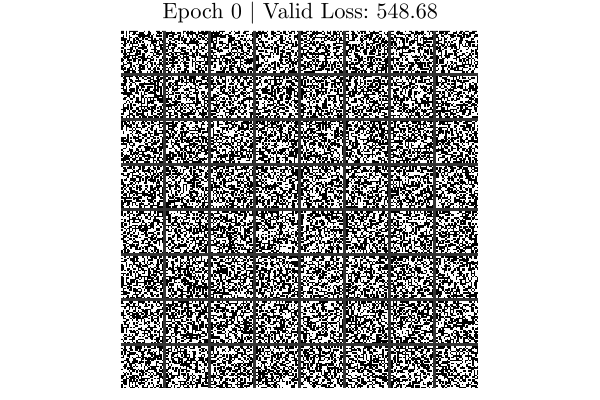

Found 14 checkpoints. Rendering plots...


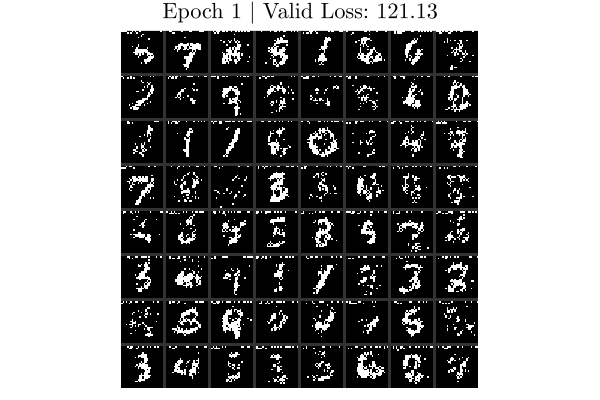

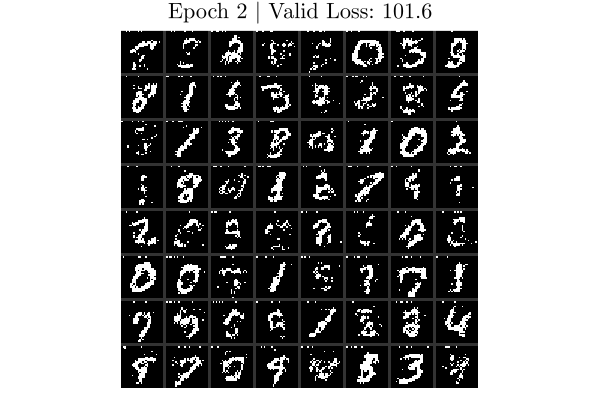

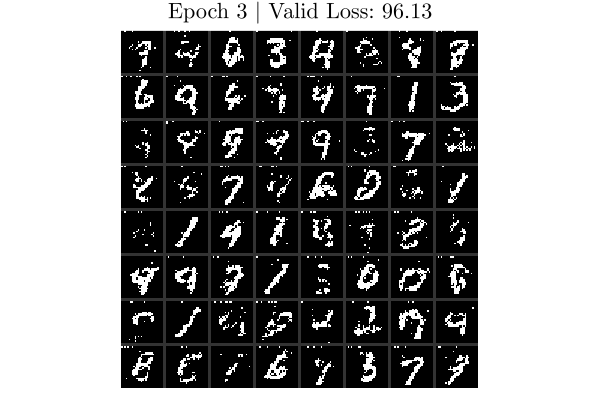

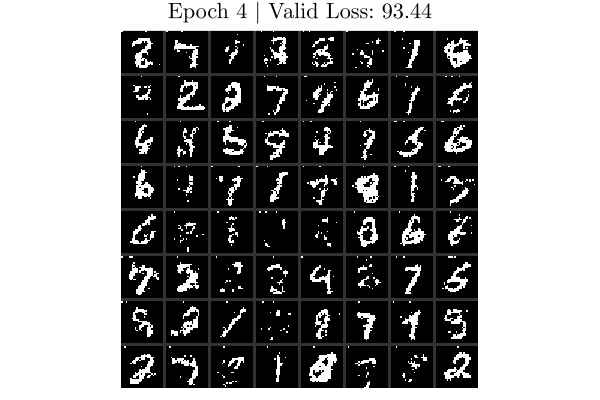

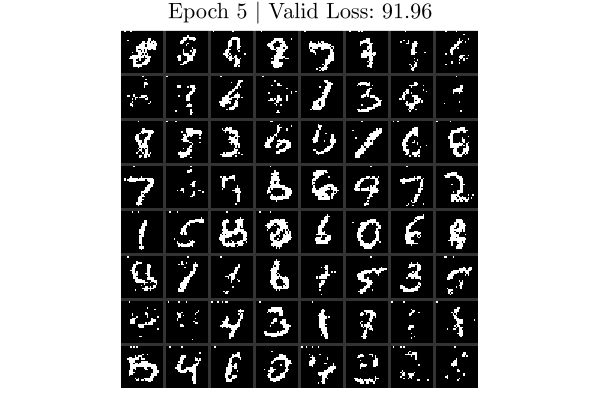

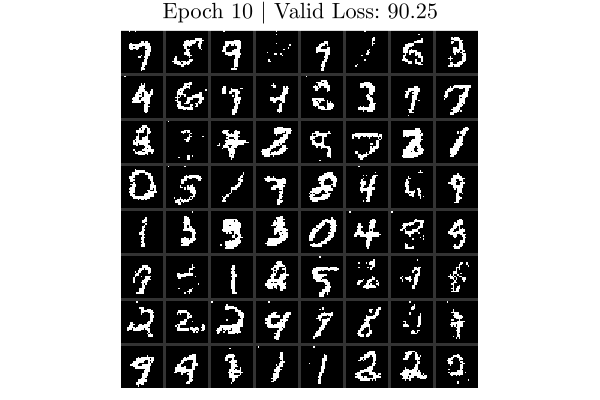

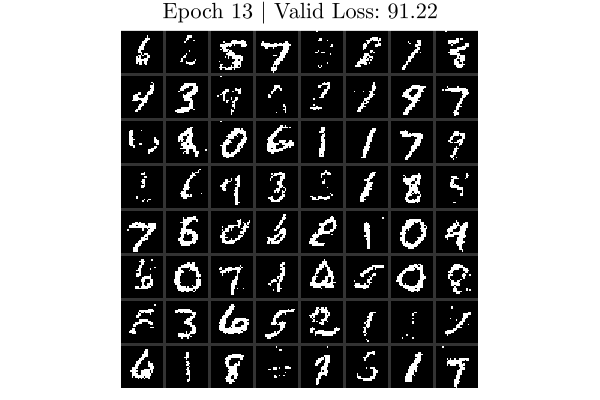

In [82]:
folder_path = "./checkpoints/MADE_d=784_res_con=true_num_masks=1_cycle_mask=true"
sample_figs = visualize_all_checkpoints(folder_path; num_samples = 64, nrows = 8);

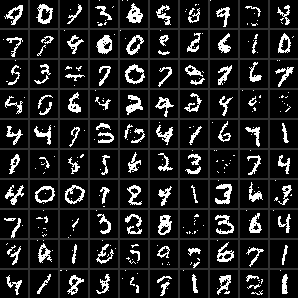

In [83]:
set_rand_seed(1234)
vec2imgs(sample(made_model_one_mask, 100); nrows=10)
# sample(made_model_one_mask, 100)
# best_made_one_mask
vec2imgs(sample(best_made_one_mask |> device, 100); nrows=10)


In [84]:
check_causal_mask(made_model_one_mask)

true

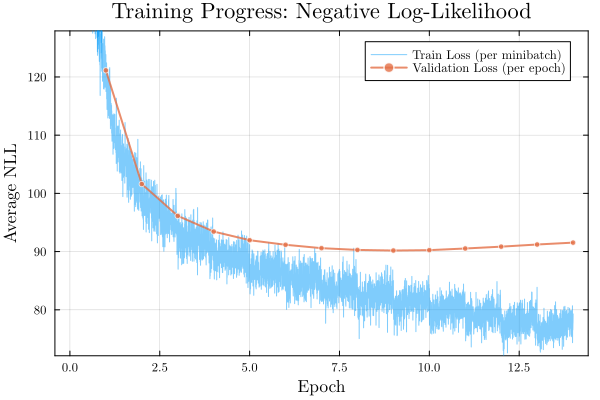

In [85]:
plot_loss_history(losses_made_one_mask, valid_loss_one_mask, mnist_binary_loader)

In [86]:
logpdf(made_model_one_mask |> device, mnist_binary_test |> device; train = false)

-90.950966f0

In [87]:
logpdf(best_made_one_mask |> device, mnist_binary_test |> device; train = false)

-89.5142f0

In [88]:
update_maskset!(made_model_one_mask)
logpdf(made_model_one_mask|> device, mnist_binary_test |> device)

-90.950966f0

In [18]:
Random.seed!(1234)
made_model_en = MADE(28^2, [8000, 8000]; act=relu, input_order=nothing, res_con=true, num_masks=20, init=Flux.kaiming_uniform) |> device
losses_made_en, valid_loss_en, best_made_en = fit!(made_model_en, mnist_binary_loader, Adam(), 50;
    valid_data=mnist_binary_valid,
    patience=30,
    every_epoch=10
)

┌ Info: Epoch 1; Loss = 215.2891
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:84
Progress:  20%|████████▎                                |  ETA: 0:03:01┌ Info: Epoch 11; Loss = 101.7193
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:84
Progress:  40%|████████████████▍                        |  ETA: 0:02:01┌ Info: Epoch 21; Loss = 93.5198
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:84
Progress:  60%|████████████████████████▋                |  ETA: 0:01:17┌ Info: Epoch 31; Loss = 89.5023
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:84
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:37┌ Info: Epoch 41; Loss = 87.0674
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:84
Progress: 100%|█████████████████████████████████████████| Time: 0:03:00


(Any[557.7318f0, 507.00415f0, 448.18677f0, 407.8346f0, 385.3669f0, 372.00568f0, 368.02704f0, 362.57324f0, 357.9682f0, 357.38254f0  …  87.20145f0, 83.68433f0, 84.9832f0, 84.71511f0, 86.43123f0, 85.638016f0, 86.027824f0, 87.083275f0, 84.14289f0, 82.24146f0], Any[163.3301f0, 141.4045f0, 135.245f0, 123.14585f0, 120.074615f0, 114.0557f0, 110.46548f0, 107.21045f0, 104.32382f0, 102.98854f0  …  94.96932f0, 94.6462f0, 95.27471f0, 95.15136f0, 95.286476f0, 95.07588f0, 95.27485f0, 95.5996f0, 95.2812f0, 95.33624f0], MADE{Parallel{typeof(+), Tuple{Chain{Tuple{MaskedDense{Float32, Vector{Float32}}, MaskedDense{Float32, Vector{Float32}}, MaskedDense{Float32, Vector{Float32}}}}, MaskedDense{Float32, Vector{Float32}}}}}(784, Parallel(+, Chain(MaskedDense{Float32, Vector{Float32}}(Float32[0.0007940054 0.0582085 … -0.07341845 -0.031959068; 0.025899705 0.04749452 … 0.021898914 0.022662967; … ; 0.010228702 0.07493787 … -0.02000865 -0.016611531; -0.07730669 0.0007408923 … 0.08221244 0.07426588], Float32[-0.0

In [43]:
check_causal_mask(made_model_en)

true

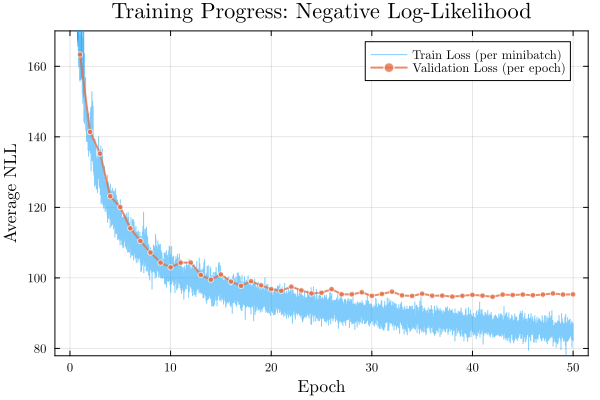

In [20]:
plot_loss_history(losses_made_en, valid_loss_en, mnist_binary_loader)

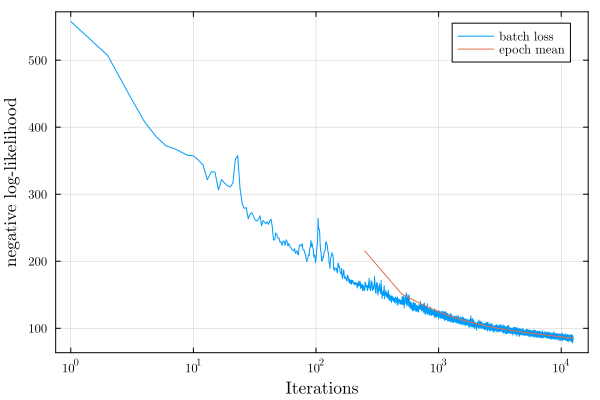

In [21]:
plot_loss(losses_made_en, length(mnist_binary_loader))

In [22]:
update_maskset!(best_made_en)
logpdf(best_made_en |> device, mnist_binary_test |> device)

-93.83243f0

In [23]:
logpdf(made_model_en |> device, mnist_binary_test |> device; train = false)

-88.46251f0

In [24]:
logpdf_test_karpathy(made_model_en |> device, mnist_binary_test.data[1] |> device)

-77.716805f0

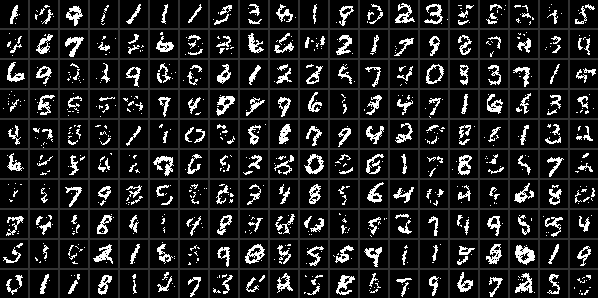

In [25]:
vec2imgs(sample(made_model_en |> device, 200); nrows=10)

In [26]:
train_loader, test_loader, valid_loader = load_mnist_data(batch_size; dtype=Bool, tensor_shape=(28*28, :))

(DataLoader(data::Tuple{Matrix{Float32}, Vector{Int64}}, shuffle=true, batchsize=200), DataLoader(data::Tuple{Matrix{Float32}, Vector{Int64}}, shuffle=true, batchsize=200), DataLoader(data::Tuple{Matrix{Float32}, Vector{Int64}}, shuffle=true, batchsize=200))

In [27]:
Random.seed!(1234)
made_model_en_new_data = MADE(28^2, [8000, 8000]; act=relu, input_order=nothing, res_con=true, num_masks=20, init=Flux.kaiming_uniform) |> device
losses_made_en_new_data, valid_losses_en_new_data, best_made_en_new_data = fit!(made_model_en_new_data, train_loader, Adam(), 50; valid_data=valid_loader, patience=20, every_epoch=15)

┌ Info: Epoch 1; Loss = 206.8119
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:84
Progress:  40%|████████████████▍                        |  ETA: 0:02:16┌ Info: Epoch 21; Loss = 92.2336
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:84
Progress:  80%|████████████████████████████████▊        |  ETA: 0:00:43┌ Info: Epoch 41; Loss = 86.644
└ @ Main /home/lf28/Julia/DeepGenModels/utils.jl:84
Progress: 100%|█████████████████████████████████████████| Time: 0:03:28


(Any[557.6258f0, 507.1899f0, 450.04462f0, 406.67157f0, 384.4513f0, 383.22086f0, 383.33337f0, 371.3789f0, 351.85364f0, 345.32404f0  …  85.278946f0, 87.02617f0, 85.5542f0, 88.85572f0, 89.69102f0, 84.742546f0, 85.47188f0, 86.453514f0, 87.65891f0, 85.45047f0], Any[165.72984f0, 133.0089f0, 122.87226f0, 115.0052f0, 111.88166f0, 109.44659f0, 104.81608f0, 102.5423f0, 103.17749f0, 103.072464f0  …  93.746765f0, 93.467766f0, 93.6179f0, 93.68849f0, 93.63404f0, 93.85783f0, 93.76204f0, 93.79881f0, 93.8288f0, 93.935326f0], MADE{Parallel{typeof(+), Tuple{Chain{Tuple{MaskedDense{Float32, Vector{Float32}}, MaskedDense{Float32, Vector{Float32}}, MaskedDense{Float32, Vector{Float32}}}}, MaskedDense{Float32, Vector{Float32}}}}}(784, Parallel(+, Chain(MaskedDense{Float32, Vector{Float32}}(Float32[0.0007940054 0.0582085 … -0.07341845 -0.031959068; 0.025899705 0.04749452 … 0.021898914 0.022662967; … ; 0.010228702 0.07493787 … -0.02000865 -0.016611531; -0.07730669 0.0007408923 … 0.08221244 0.07426588], Float32

In [28]:
logpdf(made_model_en_new_data |> device, test_loader.data[1] |> device; train = false)

-87.842316f0

In [44]:
xsamples, psamples = sample(made_model_en_new_data |> device, 200; samples_only=false)

(Float32[0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0; … ; 0.0 0.0 … 0.0 0.0; 0.0 0.0 … 0.0 0.0], Float32[1.7343893f-7 2.3664865f-7 … 1.0475307f-5 6.6764796f-6; 4.1893858f-7 1.1750071f-7 … 6.79199f-9 1.0996877f-7; … ; 1.4728386f-8 2.6385847f-9 … 2.2105843f-7 1.4243017f-7; 7.00893f-7 7.4086404f-7 … 2.0015676f-7 2.8255442f-7])

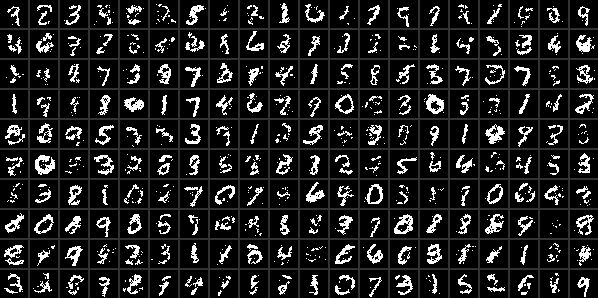

In [45]:
vec2imgs(xsamples; nrows=10) 

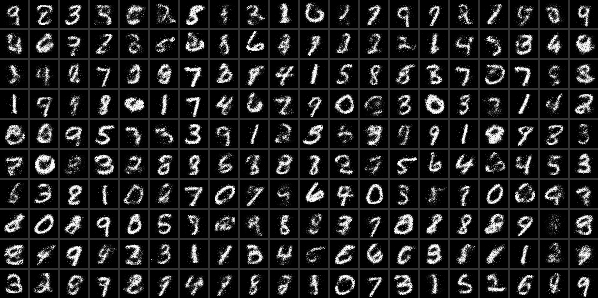

In [46]:
vec2imgs(psamples; nrows=10)

In [32]:
function _sample(model, n=1; input_order=1:(28^2))
    # xs = zeros(Bool, 28^2, n) |> device
    xs = zeros(Bool, 28^2, n) |> device

    for d in sortperm(input_order)
        # Find WHICH spatial pixel index corresponds to the current step
        # d = input_order[step]
        
        # Run the full forward pass
        logits_d = model(xs)[d, :]
        ps = σ.(logits_d)
        # Extract predictions for this specific pixel dimension across the batch
        
        # Sample and update the pixel state on the device
        xs[d, :] = rand_like(ps) .< ps
    end

    return xs 
end

function logpdf(model::Chain, xs; reduction=mean)
    xs_preds = model(xs)
    logL = -Flux.logitbinarycrossentropy(xs_preds, xs; agg=identity)
    logL = sum(logL, dims=1)
    logL |> reduction
end

logpdf (generic function with 3 methods)

In [33]:
begin
    Random.seed!(1234)
    hidden_size = 28^2
    # hidden_order = sort(rand(1:28^2-1, hidden_size))
    hidden_order = sort(rand(1:(28^2-1), hidden_size))

    input_order = shuffle([1:(28^2);])
    md = MaskedDense(28^2, hidden_size, input_order, hidden_order; act=relu, output_layer=false)
    out_layer = MaskedDense(hidden_size, 28^2, hidden_order, input_order; act=identity, output_layer=true)
    made1 = Chain(md, out_layer) |> device
    opt = Flux.setup(Adam(0.001), made1)
    losses = []

    @showprogress for epoch in 1:20
        for (xs,) in mnist_binary_loader
            xs = xs |> device
            li, gs = Flux.withgradient(made1) do m
                preds = m(xs)
                sum(Flux.logitbinarycrossentropy(preds, xs; agg=identity), dims=1) |> mean
            end
            Flux.update!(opt, made1, gs[1])
            push!(losses, li)
        end
    end
end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:08


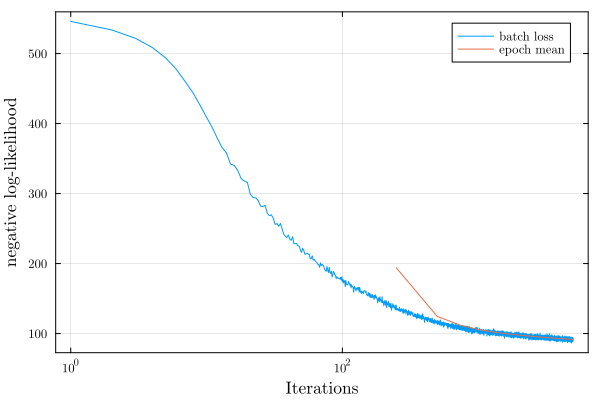

In [34]:
plot_loss(losses, length(mnist_binary_loader))

In [35]:
function _sample!(xs, model; input_order=1:(28^2))
    # xs = zeros(Bool, 28^2, n) |> device
    # model = model 
    # xs = xs 
    for d in sortperm(input_order)
        ps = σ(model(xs)[d, :])
        xs[d, :] .= rand_like(ps) .< ps
    end

    return xs 
end

_sample! (generic function with 1 method)

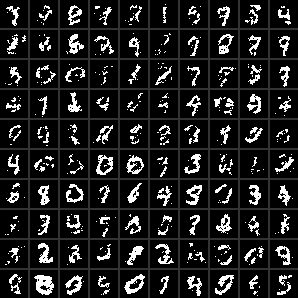

In [36]:
begin
    xs = zeros(Bool, 784, 100) |> device
    xs = _sample!(xs, made1; input_order=input_order)

    # vec2imgs(xs; nrows= 10)
    # vec2imgs(xs; nrows=10)

    vec2imgs(xs; nrows = 10)
end

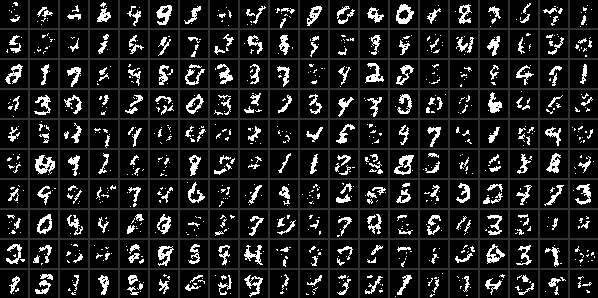

In [37]:
vec2imgs(_sample(made1, 200; input_order= input_order); nrows=10)

In [47]:
logpdf(made1, mnist_binary_test.data[1] |> device)

-94.08555f0

In [39]:
begin
    Random.seed!(1234)
    hidden_size = 500
    # hidden_order = sort(rand(1:28^2-1, hidden_size))
    # hidden_order = shuffle(1:28^2-1)[1:hidden_size]
    hidden_order = rand(1:28^2-1, hidden_size)
    input_order = shuffle([1:28^2;])
    path1 = Chain(MaskedDense(28^2, hidden_size, input_order, hidden_order; act = tanh, output_layer =false), 
        MaskedDense(hidden_size, 28^2, hidden_order, input_order; act = identity,output_layer =true))

    path2 = MaskedDense(28^2, 28^2, input_order, input_order; act = identity, output_layer =true)
    made2_res = Parallel(+; path1, path2) |> device
    opt = Flux.setup(AdamW(0.001, (0.9, 0.999), 3e-4, couple=false), made2_res)
    losses2 = []


    @showprogress for epoch in 1:20
        for (xs, ) in mnist_binary_loader
            xs = xs |> device
            li, gs = Flux.withgradient(made2_res) do m
                preds = m(xs)
                sum(Flux.logitbinarycrossentropy(preds, xs; agg = identity), dims=1) |> mean
            end
            Flux.update!(opt, made2_res, gs[1])
            push!(losses2, li)
        end
    end
end

Progress: 100%|█████████████████████████████████████████| Time: 0:00:14


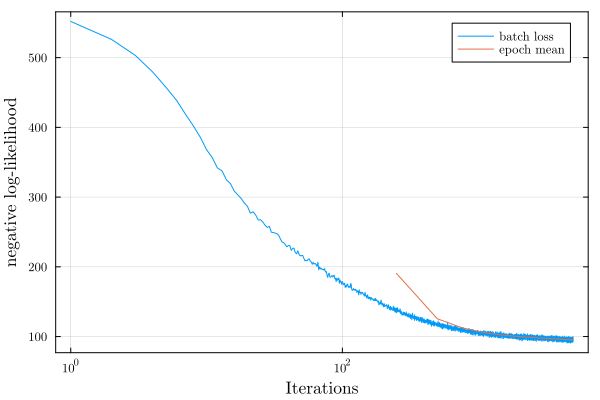

In [40]:
# plot(losses2, xscale=:log10, fmt=:svg, label="", xlabel="Epoch")
plot_loss(losses2, length(mnist_binary_loader))

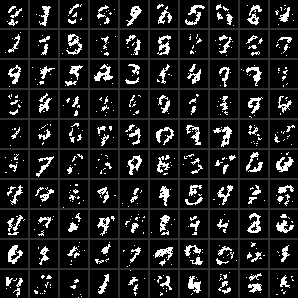

In [41]:
vec2imgs(_sample(made2_res, 100; input_order= input_order); nrows=10)